In [2]:
import scanpy as sc
import pandas as pd
import os
import numpy as np
from pathlib import Path

In [3]:
dataset = "human_brain"
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)
fig_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", "figures")

In [5]:
# --- I/O ---
adata = sc.read_h5ad(os.path.join(res_path, "replicates.h5ad"))        # corresponds to readH5AD(...)
mdata = pd.read_csv(os.path.join(res_path, "cell_metadata.csv"))       # has a column 'cell_types'

In [6]:
adata.shape

(14753, 17999)

In [7]:
# --- Build metadata to mirror your R code ---
# R uses: meta.data = data.frame(method = data0$replicate_id, cell_type=m.data$cell_types)
# Make sure cell order aligns with adata.obs_names (R used colnames(counts)).
if len(mdata) != adata.n_obs:
    raise ValueError("cell_metadata.csv row count doesn't match number of cells in replicates.h5ad.")

adata.obs["method"] = adata.obs["replicate_id"].astype(str)  # e.g. "4", "1"
adata.obs["cell_type"] = mdata["cell_types"].astype("category")

# --- Mimic Seurat's CreateSeuratObject(min.cells=3, min.features=10) ---
# min.features=10 => keep cells with at least 10 detected genes
sc.pp.filter_cells(adata, min_genes=10)
# min.cells=3 => keep genes expressed in at least 3 cells
sc.pp.filter_genes(adata, min_cells=3)

# --- Keep only the two methods used in your script: "4" and "1" ---
keep_methods = ["4", "1"]
adata = adata[adata.obs["method"].isin(keep_methods)].copy()

# Relabel methods to match your R 'data1' (X1) and 'data2' (X2)
# In your R, X1 <- method=="4", X2 <- method=="1"
adata.obs["method"] = adata.obs["method"].map({"4": "data1", "1": "data2"}).astype("category")

In [9]:
# --- Normalize to match Seurat NormalizeData(LogNormalize, scale.factor=1e4) ---
sc.pp.normalize_total(adata, target_sum=1e4)   # library-size normalize
sc.pp.log1p(adata)                             # log1p like Seurat's log-normalize output

# --- Highly variable genes like Seurat v3 across batches, n=1000 ---
# This is the Python analog of:
#   FindVariableFeatures(..., selection.method="vst") per batch
#   SelectIntegrationFeatures(object.list, nfeatures=1000)
sc.pp.highly_variable_genes(
    adata,
    flavor="seurat_v3",
    n_top_genes=1000,
    batch_key="method"
)

# Subset to the selected integration features
hv_mask = adata.var["highly_variable"].to_numpy()
adata_hv = adata[:, hv_mask].copy()

/gpfs01/berens/user/sdamrich/mirrored_code/ne_aligned/.venv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)


In [10]:

# --- Split matrices for data1 (X1) and data2 (X2) in the same gene order ---
X1 = adata_hv[adata_hv.obs["method"] == "data1"].X
X2 = adata_hv[adata_hv.obs["method"] == "data2"].X

# Ensure dense arrays for saving (your R code uses as.matrix(...))
X1 = X1.toarray() if hasattr(X1, "toarray") else np.asarray(X1)
X2 = X2.toarray() if hasattr(X2, "toarray") else np.asarray(X2)

features = adata_hv.var_names.to_list()  # 1000 selected genes
obs_out = adata_hv.obs.copy()

In [45]:
adata.obs.keys()

Index(['replicate_id', 'doublet', 'total_UMIs', 'total_MT_UMIs', 'pct_MT_UMIs',
       'total_genes', 'method', 'cell_type', 'n_genes'],
      dtype='object')

In [14]:

# --- Save outputs for Python workflows ---
outdir = res_path

np.save(os.path.join(res_path, "X1.npy"), X1)                     # normalized log-expression, genes x cells implied by shape
np.save(os.path.join(res_path, "X2.npy"), X2)
pd.Series(features, name="gene").to_csv(os.path.join( res_path, "features.txt"), index=False)
obs_out.to_csv(os.path.join( res_path,  "cells_metadata.csv")  )    # includes cell_type and method
adata_hv.write(os.path.join( res_path, "combined_1000genes.h5ad")) # convenient all-in-one AnnData file

In [16]:
X1.shape, X2.shape

((3145, 1000), (6070, 1000))

In [19]:
from openTSNE import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [17]:
pca1_50 = PCA(n_components=50).fit_transform(X1)
pca2_50 = PCA(n_components=50).fit_transform(X2)
pcaj_50 = PCA(n_components=50).fit_transform(np.concatenate((X1, X2)))

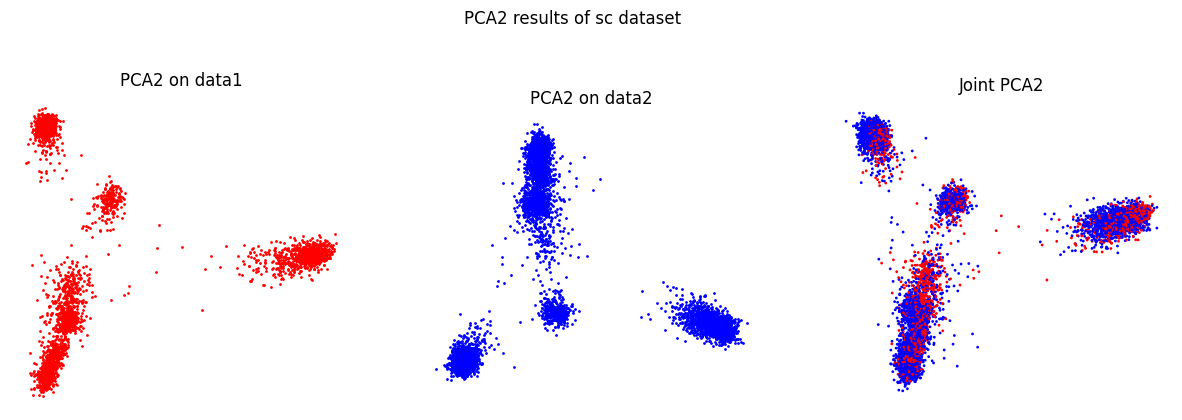

In [28]:


fig, ax = plt.subplots(1,3, figsize=(15,5))
ax[0].scatter(*pca1_50[:, :2].T, s=1, c="r")
ax[0].set_title("PCA2 on data1")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("PCA2 on data2")
ax[1].scatter(*pca2_50[:, :2].T, s=1, c="b")
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("Joint PCA2")

order = np.random.permutation(pcaj_50.shape[0])
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
ax[2].scatter(*pcaj_50[order, :2].T, s=1, c=np.array(colors)[order])
ax[2].set_aspect("equal")
ax[2].axis("off")


fig.suptitle("PCA2 results of sc dataset")

fig.savefig(os.path.join(fig_path, "sc_pca2.png"), dpi=300)

In [18]:
tsne1 = TSNE(verbose=True).fit(pca1_50)
tsne2 = TSNE(verbose=True).fit(pca2_50)
tsnej = TSNE(verbose=True).fit(pcaj_50)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 1.17 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.10 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.24 seconds
===> Running optimization with exaggeration=12.00, lr=262.08 for 250 iterations...
Iteration   50, KL divergence 2.8363, 50 iterations in 4.6527 sec
Iteration  100, KL divergence 2.7409, 50 iterations in 4.2352 sec
Iteration  150, KL divergence 2.6996, 50 iterations in 3.9293 sec
Iteration  200, KL divergence 2.6789, 50 iterations in 4.0364 sec
Iteration  250, KL divergence 2.6671, 50 iterations in 4.3233 sec
   --> Time elapsed: 21.18 seconds
===> Running optimization with exaggeration=1.00, lr=3145.00 for 500 ite

(np.float64(-76.23418222273388),
 np.float64(74.74619253227053),
 np.float64(-80.16934006731476),
 np.float64(65.76221545713463))

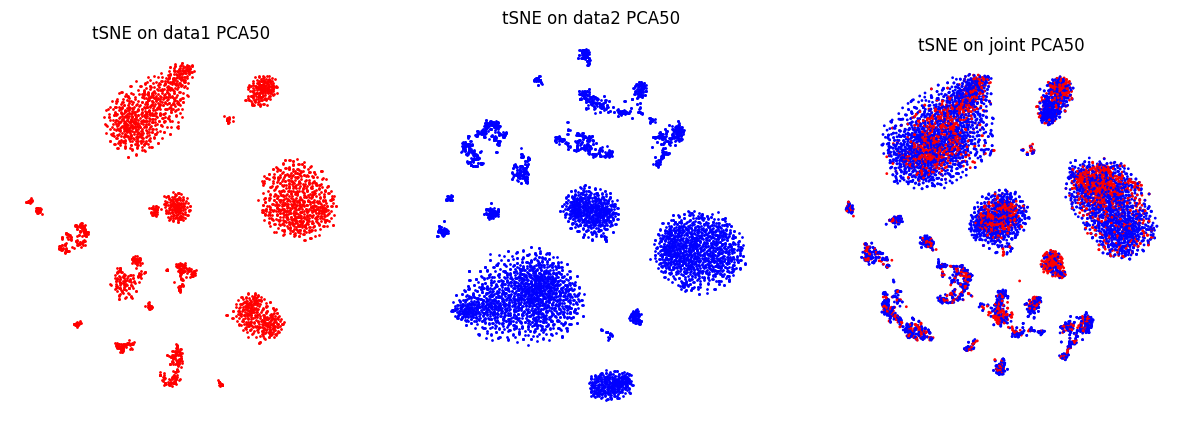

In [29]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].scatter(*tsne1.T, s=1, c="r")
ax[0].set_title("tSNE on data1 PCA50")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("tSNE on data2 PCA50")
ax[1].scatter(*tsne2.T, s=1, c="b")
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("tSNE on joint PCA50")
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
order = np.random.permutation(len(colors))
ax[2].scatter(*tsnej[order].T, s=1, c=np.array(colors)[order])
ax[2].set_aspect("equal")
ax[2].axis("off")


In [30]:
# OT

In [37]:
from ne_aligned_utils.utils import compute_ot_plan, sparsify_plan, get_bipartite_graph
from openTSNE.affinity import Affinities


In [33]:
eps_times = 1
tol = 1e-12
maxIter = int(1e4)
sparsify = "topk"

In [34]:
P = compute_ot_plan(X1, X2, eps_times=eps_times, tol=tol, maxIter=maxIter)

In [35]:
P_sparse = sparsify_plan(P, mode=sparsify, k=15)

In [36]:
graph = get_bipartite_graph(P_sparse)
graph.sum_duplicates()
graph /= graph.sum()

In [38]:
init = pcaj_50[:, :2]
init /= init[:, 0].std() * 10000
n_epochs = 750
embd_dim = 2
seed = 0

# compute embedding
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)
affinities = Affinities()
affinities.P = graph.tocsr()

embd = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=767.92 for 250 iterations...
Iteration   50, KL divergence 4.9925, 50 iterations in 22.9804 sec
Iteration  100, KL divergence 4.6503, 50 iterations in 18.9629 sec
Iteration  150, KL divergence 4.6069, 50 iterations in 18.7070 sec
Iteration  200, KL divergence 4.5567, 50 iterations in 18.7727 sec
Iteration  250, KL divergence 4.5704, 50 iterations in 18.6785 sec
   --> Time elapsed: 98.10 seconds
===> Running optimization with exaggeration=1.00, lr=9215.00 for 500 iterations...
Iteration   50, KL divergence 3.5344, 50 iterations in 14.5496 sec
Iteration  100, KL divergence 3.4491, 50 iterations in 12.8550 sec
Iteration  150, KL divergence 3.4135, 50 iterations in 12.7117 sec
Iteration  200, KL divergence 3.3888, 50 it

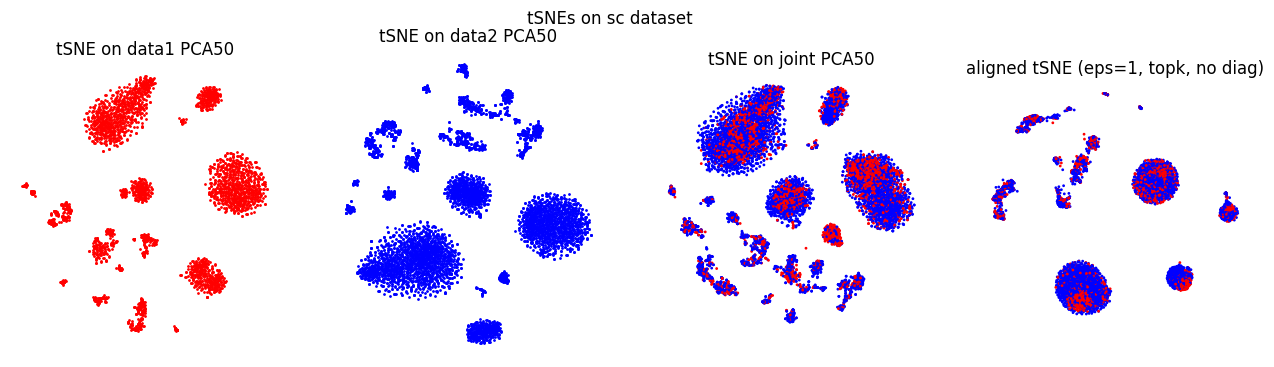

In [42]:
fig, ax = plt.subplots(1,4, figsize=(16, 4))

ax[0].scatter(*tsne1.T, s=1, c="r")
ax[0].set_title("tSNE on data1 PCA50")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("tSNE on data2 PCA50")
ax[1].scatter(*tsne2.T, s=1, c="b")
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("tSNE on joint PCA50")
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
order = np.random.permutation(len(colors))
ax[2].scatter(*tsnej[order].T, s=1, c=np.array(colors)[order])
ax[2].set_aspect("equal")
ax[2].axis("off")

ax[3].set_title("aligned tSNE (eps=1, topk, no diag)")
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
order = np.random.permutation(len(colors))
ax[3].scatter(*embd[order].T, s=1, c=np.array(colors)[order])
ax[3].set_aspect("equal")
ax[3].axis("off")

fig.suptitle("tSNEs on sc dataset")
fig.savefig(os.path.join(fig_path, "sc_tsne.png"), dpi=300)